# Lab 04 · What do the graph and the profiles add? (ablation)

**Roadmap P4.6 · CO4 + CO6.** The departures champion from Lab 02, with its exact configuration, is refit
on August with whole feature groups removed, and scored on September:
- the **graph** group: GraphX PageRank, strengths, clustering and districts;
- the **profile** group: the station's own hour-of-week history;
- both of them;
- the **weather** group.

The difference in MAE is what each group contributes. This is analysis after the model was chosen: nothing
here feeds back into the choice.

In [1]:
import json

import matplotlib.pyplot as plt
from pyspark.ml import Pipeline
from pyspark.ml.regression import DecisionTreeRegressor, GBTRegressor, LinearRegression, RandomForestRegressor

from velograph.common.serving import write_serving
from velograph.common.settings import data_paths
from velograph.lab import metrics
from velograph.lab.features import load_dictionary, load_splits, prep_stages
from velograph.lab.session import lab_session

spark = lab_session("04-ablation")
d = load_dictionary()
s = load_splits(spark)
regression = json.loads((data_paths().serving / "ml-regression.json").read_text(encoding="utf-8"))["data"]

TARGET = "departures"
ESTIMATORS = {
    "linear-regression": (True, LinearRegression),
    "decision-tree": (False, DecisionTreeRegressor),
    "random-forest": (False, RandomForestRegressor),
    "gbt": (False, GBTRegressor),
}
algo = regression["targets"][TARGET]["champion"]
params = next(r["params"] for r in regression["targets"][TARGET]["leaderboard"] if r["model"] == algo)
fixed = regression["fixedParams"][algo]
print("champion:", algo, params, fixed)

champion: random-forest {'numTrees': 30, 'maxDepth': 12} {'minInstancesPerNode': 20, 'maxMemoryInMB': 1024, 'cacheNodeIds': True, 'seed': 315, 'subsamplingRate': 0.5}


In [2]:
VARIANTS = [
    ("all features", ()),
    ("without graph", ("graph",)),
    ("without profiles", ("profile",)),
    ("without graph or profiles", ("graph", "profile")),
    ("without weather", ("weather",)),
]
linear, estimator = ESTIMATORS[algo]
variants = []
for name, dropped in VARIANTS:
    stages = prep_stages(d, linear=linear, drop_groups=dropped)
    model = estimator(featuresCol="features", labelCol=TARGET, **fixed, **params)
    test = metrics.regression(Pipeline(stages=[*stages, model]).fit(s.fit).transform(s.test), TARGET)
    variants.append(
        {"name": name, "dropped": list(dropped), "features": len(d.names(drop_groups=dropped)), "test": test}
    )
    print(
        f"{name:>26}: {variants[-1]['features']} features · test MAE {test['mae']:.4f} · R² {test['r2']:.4f}"
    )

full = variants[0]["test"]
for v in variants:
    v["deltaMae"] = round(v["test"]["mae"] - full["mae"], 5)
    v["deltaMaePct"] = round((v["test"]["mae"] - full["mae"]) / full["mae"] * 100, 2)
    v["deltaR2"] = round(v["test"]["r2"] - full["r2"], 5)
naive = regression["targets"][TARGET]["baselines"]["seasonal-naive"]["test"]

              all features: 31 features · test MAE 1.4595 · R² 0.7454


             without graph: 22 features · test MAE 1.4829 · R² 0.7285


          without profiles: 26 features · test MAE 1.5526 · R² 0.7108


 without graph or profiles: 17 features · test MAE 1.8438 · R² 0.5858


           without weather: 24 features · test MAE 1.5705 · R² 0.7045


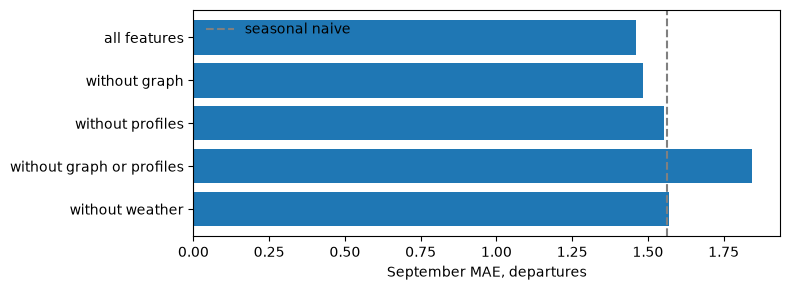

             without graph: MAE +1.6 % against all features
          without profiles: MAE +6.4 % against all features
 without graph or profiles: MAE +26.3 % against all features
           without weather: MAE +7.6 % against all features


In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
names = [v["name"] for v in variants]
ax.barh(names, [v["test"]["mae"] for v in variants])
ax.axvline(naive["mae"], linestyle="--", color="grey", label="seasonal naive")
ax.invert_yaxis()
ax.set_xlabel("September MAE, departures")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
for v in variants[1:]:
    print(f"{v['name']:>26}: MAE {v['deltaMaePct']:+.1f} % against all features")

In [4]:
path = write_serving(
    data_paths().serving / "ml-ablation.json",
    "ml-ablation",
    "lab-04-ablation",
    {
        "target": TARGET,
        "model": algo,
        "params": params,
        "fixedParams": fixed,
        "naive": naive,
        "variants": variants,
    },
    rows=s.test.count(),
    source={"from": d.report["windows"][0]["profile"]["from"], "to": d.report["windows"][1]["rows"]["to"]},
)
print("wrote", path)

wrote C:\Users\Sayan\Desktop\int315\data\serving\ml-ablation.json


In [5]:
spark.stop()